# Лабораторная работа №8: Active learning и human-in-the-loop

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать random, entropy и diversity sampling.
- Провести несколько AL-итераций.
- Построить learning curves при равном бюджете.


## Теоретическая часть

Active learning выбирает следующий batch из pool. Uncertainty ищет неуверенные объекты, diversity покрывает пространство, disagreement использует расхождение моделей. Сравнение корректно только при одинаковом annotation budget.


### Математическая постановка

Entropy sampling: $u(x)=-\sum_c p(c\mid x)\log p(c\mid x)$. Diversity можно реализовать k-center: выбрать объект, максимизирующий расстояние до уже размеченного множества.


### Материалы

- [Active Learning survey](https://arxiv.org/abs/2009.00236)
- [scikit-learn calibration](https://scikit-learn.org/stable/modules/calibration.html)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Работа выполняется на изображениях рукописных цифр `sklearn.datasets.load_digits`; oracle в этом воспроизводимом эксперименте симулирует человека, открывая истинную метку только после отбора объекта. FAST_DEV_RUN — два раунда проверки кода, полный режим — восемь раундов и повторный random baseline.

In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
# Отдельная подпапка: в artifacts/ лежат результаты лабораторной №1, в artifacts/lab2–lab7 — №2–№7.
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts/lab8"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
# PNG-файлы ошибочных test-примеров (пути попадают в test_errors.json) храним внутри папки лабораторной
LAB_IMAGES = ARTIFACTS / "images"
LAB_IMAGES.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)

def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT),
       "artifacts": str(ARTIFACTS), "lab_images": str(LAB_IMAGES)})

{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\bogom\\OneDrive\\Документы\\PSY\\6 курс\\МО\\data', 'artifacts': 'artifacts\\lab8', 'lab_images': 'artifacts\\lab8\\images'}


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Задание 1. Стратифицированный отложенный тест

*Вес: 1 балл.*

**Постановка.** Этап «стратифицированный отложенный тест» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Разделите изображения цифр по стратифицированному правилу до выбора стратегии.
2. Сохраните и предъявите индексы train/test изображений цифр.

**Результат.** индексы train/test изображений цифр.

**Критерий принятия.** Задание считается принятым, если индексы train/test изображений цифр получены из фактических входов этого этапа и доступны для проверки.

**Задание 1. Стратифицированный отложенный тест**

**Что делали**: разделили 1797 изображений `load_digits` на train 1347 и test 450 через `train_test_split(test_size=0.25, stratify=y, random_state=42)`. Разделение сделано до выбора стратегий.<br>
**Зачем**: получить один фиксированный test для всех стратегий, где доли цифр такие же, как в train. Тогда сравнение стратегий честное.<br>
**Результат**: файл `holdout_split.json` с индексами train/test. В test 43–46 изображений каждой цифры, в train 131–137. Пересечений нет, все проверки ✔.

In [2]:
# Стратифицированный отложенный тест: делим изображения цифр ДО выбора AL-стратегии
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X_all = digits.data.astype(np.float32) / 16.0   # 8x8 пикселей, яркость 0..16 -> 0..1
y_all = digits.target
IMAGES_ALL = digits.images                       # исходные 8x8 изображения (для разбора ошибок)
CLASSES = [int(c) for c in digits.target_names]

TEST_SIZE = 0.25
all_idx = np.arange(len(y_all))
train_idx, test_idx = train_test_split(all_idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
train_idx, test_idx = np.sort(train_idx), np.sort(test_idx)

# Проверки: разбиение полное, без пересечений, доли классов в train/test совпадают
assert len(np.intersect1d(train_idx, test_idx)) == 0
assert len(train_idx) + len(test_idx) == len(y_all)
train_counts = np.bincount(y_all[train_idx], minlength=len(CLASSES))
test_counts = np.bincount(y_all[test_idx], minlength=len(CLASSES))
assert np.abs(train_counts / len(train_idx) - test_counts / len(test_idx)).max() < 0.01

holdout_split = {
    "dataset": "sklearn.datasets.load_digits",
    "n_total": int(len(y_all)), "image_shape": list(IMAGES_ALL.shape[1:]),
    "rule": f"train_test_split(test_size={TEST_SIZE}, stratify=y, random_state={SEED})",
    "made_before_strategy_choice": True,
    "train_idx": train_idx.tolist(), "test_idx": test_idx.tolist(),
    "class_counts": {"train": dict(zip(CLASSES, train_counts.tolist())),
                     "test": dict(zip(CLASSES, test_counts.tolist()))},
}
save_json("holdout_split.json", holdout_split)
print({"train": len(train_idx), "test": len(test_idx)})
print("train по классам:", train_counts.tolist())
print("test  по классам:", test_counts.tolist())
print("Сохранено:", ARTIFACTS / "holdout_split.json")

{'train': 1347, 'test': 450}
train по классам: [133, 136, 133, 137, 136, 136, 136, 134, 131, 135]
test  по классам: [45, 46, 44, 46, 45, 46, 45, 45, 43, 45]
Сохранено: artifacts\lab8\holdout_split.json


### Задание 2. Начальная размеченная выборка

*Вес: 1 балл.*

**Постановка.** Этап «начальная размеченная выборка» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Задайте initial с каждым классом и неразмеченный pool только из train.
2. Сохраните и предъявите непересекающиеся initial и pool.

**Результат.** непересекающиеся initial и pool.

**Критерий принятия.** Задание считается принятым, если непересекающиеся initial и pool получены из фактических входов этого этапа и доступны для проверки.

**Задание 2. Начальная размеченная выборка**

**Что делали**: из train взяли initial — по 2 изображения каждой цифры (20 штук, seed 42). Остальные 1327 изображений train стали неразмеченным pool.<br>
**Зачем**: модели нужна стартовая выборка, в которой есть все 10 цифр. Pool — запас, из которого стратегии выбирают изображения для разметки.<br>
**Результат**: файл `initial_pool.json`. Initial 20, pool 1327; initial и pool не пересекаются друг с другом и с test. Все проверки ✔.

In [3]:
# Начальная размеченная выборка (initial) и неразмеченный pool — только из train
N_INIT_PER_CLASS = 2      # по 2 изображения каждой цифры -> 20 размеченных на старте
rng_init = np.random.default_rng(SEED)

initial_idx = np.sort(np.concatenate([
    rng_init.choice(train_idx[y_all[train_idx] == c], size=N_INIT_PER_CLASS, replace=False)
    for c in CLASSES
]))
pool_idx = np.setdiff1d(train_idx, initial_idx)   # всё остальное из train — неразмеченный pool
if FAST_DEV_RUN:   # для проверки механики уменьшаем pool, отчётный запуск — с полным pool
    pool_idx = np.sort(rng_init.choice(pool_idx, size=min(300, len(pool_idx)), replace=False))

# Проверки: initial и pool не пересекаются, не трогают test, initial содержит все классы
assert len(np.intersect1d(initial_idx, pool_idx)) == 0
assert len(np.intersect1d(np.concatenate([initial_idx, pool_idx]), test_idx)) == 0
assert set(y_all[initial_idx].tolist()) == set(CLASSES)

initial_pool = {
    "source": "train_idx из holdout_split.json",
    "rule": f"{N_INIT_PER_CLASS} случайных изображения на класс (rng seed={SEED}); pool = train минус initial",
    "fast_dev_run": FAST_DEV_RUN,
    "initial_idx": initial_idx.tolist(), "pool_idx": pool_idx.tolist(),
    "n_initial": int(len(initial_idx)), "n_pool": int(len(pool_idx)),
    "initial_class_counts": dict(zip(CLASSES, np.bincount(y_all[initial_idx], minlength=len(CLASSES)).tolist())),
    "intersection_initial_pool": 0, "intersection_with_test": 0,
}
save_json("initial_pool.json", initial_pool)
print({"initial": len(initial_idx), "pool": len(pool_idx), "test": len(test_idx)})
print("initial по классам:", initial_pool["initial_class_counts"])
print("Сохранено:", ARTIFACTS / "initial_pool.json")

{'initial': 20, 'pool': 1327, 'test': 450}
initial по классам: {0: 2, 1: 2, 2: 2, 3: 2, 4: 2, 5: 2, 6: 2, 7: 2, 8: 2, 9: 2}
Сохранено: artifacts\lab8\initial_pool.json


| часть | сколько | что это |
|---|---|---|
| **initial** | 20 (по 2 каждой цифры) | стартовый размеченный набор: на нём модель обучается самый первый раз |
| **pool** | 1327 | всё остальное из train: неразмеченный запас, из которого стратегии выбирают изображения в раундах |

### Задание 3. Протокол симулированного разметчика

*Вес: 1 балл.*

**Постановка.** Этап «протокол симулированного разметчика» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните split и документируйте, что oracle открывает метку лишь после выбора.
2. Сохраните и предъявите artifacts/split.json с происхождением меток.

**Результат.** artifacts/split.json с происхождением меток.

**Критерий принятия.** Задание считается принятым, если artifacts/split.json с происхождением меток получены из фактических входов этого этапа и доступны для проверки.

Oracle (по-английски «оракул», тот, кто знает ответ) — это симулированный разметчик, то есть код, который играет роль человека. Стратегия выбирает картинку, отдаёт её oracle, и он говорит, какая это цифра.

**Задание 3. Протокол симулированного разметчика**

**Что делали**: написали класс `SimulatedOracle`: он хранит скрытые метки и открывает метку только для уже выбранного изображения, записывая каждое открытие в журнал. Задали бюджет: 8 раундов × 10 изображений = 80 запросов.<br>
**Зачем**: исключить подглядывание: стратегия выбирает изображения, не зная их меток, а метки test не выдаются вовсе.<br>
**Результат**: файл `split.json` с индексами всех частей, бюджетом и разделом `label_provenance` — откуда берутся метки initial, pool и test. Проверка: попытка разметить test отклоняется ✔.

In [4]:
# Протокол симулированного разметчика (oracle)
# Метки train хранятся только внутри oracle; стратегия видит лишь признаки X_all[pool]
# и получает метку объекта только после того, как выбрала его (вызов oracle.label).
class SimulatedOracle:
    def __init__(self, y, allowed_idx):
        self._y = np.asarray(y)                    # скрытые истинные метки
        self._allowed = set(int(i) for i in allowed_idx)
        self.log = []                              # журнал: какие метки, когда и для кого открыты

    def label(self, idx, strategy, round_no):
        idx = [int(i) for i in np.atleast_1d(idx)]
        assert all(i in self._allowed for i in idx), "oracle размечает только train (initial + pool)"
        labels = self._y[idx]
        for i, lab in zip(idx, labels):
            self.log.append({"idx": i, "label": int(lab), "strategy": strategy, "round": round_no,
                             "revealed_after_selection": True})
        return labels

N_ROUNDS = 2 if FAST_DEV_RUN else 8    # число AL-раундов (по протоколу лабораторной)
BATCH_SIZE = 10                        # меток, запрашиваемых за один раунд
BUDGET = N_ROUNDS * BATCH_SIZE         # общий бюджет запросов, одинаковый для всех стратегий

# Проверка протокола: метки initial открывает oracle, а не прямое обращение к y
_check_oracle = SimulatedOracle(y_all, np.concatenate([initial_idx, pool_idx]))
assert np.array_equal(_check_oracle.label(initial_idx, "initial", 0), y_all[initial_idx])
try:
    _check_oracle.label(test_idx[:1], "check", 0); raise RuntimeError("oracle не должен размечать test")
except AssertionError:
    pass

split = {
    "dataset": "sklearn.datasets.load_digits",
    "seed": SEED, "fast_dev_run": FAST_DEV_RUN,
    "train_idx": train_idx.tolist(), "test_idx": test_idx.tolist(),
    "initial_idx": initial_idx.tolist(), "pool_idx": pool_idx.tolist(),
    "label_provenance": {
        "initial": "истинные метки load_digits, открыты oracle до первого раунда (round=0)",
        "pool": "метки скрыты; oracle открывает истинную метку load_digits только для объекта, "
                "уже выбранного стратегией, и пишет запись в журнал (strategy, round, idx, label)",
        "test": "истинные метки load_digits; используются только для оценки accuracy, "
                "не доступны стратегиям и не запрашиваются у oracle",
    },
    "oracle": {"type": "simulated human annotator", "noise": 0.0,
               "reveals_label_only_after_selection": True, "can_label_test": False},
    "budget": {"n_rounds": N_ROUNDS, "batch_size": BATCH_SIZE, "total_queries": BUDGET,
               "n_initial": int(len(initial_idx))},
}
save_json("split.json", split)
print({"initial": len(initial_idx), "pool": len(pool_idx), "test": len(test_idx),
       "rounds": N_ROUNDS, "batch": BATCH_SIZE, "budget": BUDGET})
print("Сохранено:", ARTIFACTS / "split.json")

{'initial': 20, 'pool': 1327, 'test': 450, 'rounds': 8, 'batch': 10, 'budget': 80}
Сохранено: artifacts\lab8\split.json


### Задание 4. Три стратегии запроса

*Вес: 1 балл.*

**Постановка.** Этап «три стратегии запроса» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Реализуйте случайный, энтропийный и k-center выбор; в k-center обновляйте расстояния после каждого объекта.
2. Сохраните и предъявите выбор random, entropy и k-center.

**Результат.** выбор random, entropy и k-center.

**Критерий принятия.** Задание считается принятым, если выбор random, entropy и k-center получены из фактических входов этого этапа и доступны для проверки.

**Задание 4. Три стратегии запроса**

**Что делали**: реализовали random, entropy и k-center (в k-center расстояния пересчитываются после каждого выбранного изображения). Для демонстрации обучили модель на 20 изображениях initial (accuracy на test 0.773), и каждая стратегия выбрала по 10 изображений.<br>
**Зачем**: проверить, что стратегии работают и выбирают разные изображения, ещё до полного цикла обучения.<br>
**Результат**: файл `query_selection.json`. Random выбрал 7 разных цифр, k-center — 6, entropy — 2 (9 восьмёрок и одну тройку). Средняя энтропия выбранных entropy — 2.233 против 1.885 по всему pool.

In [5]:
# Три стратегии запроса: random, entropy, k-center
# Все функции получают только индексы pool и признаки/вероятности — истинные метки им не нужны.
from sklearn.linear_model import LogisticRegression

def make_model():
    # Один и тот же классификатор для всех стратегий
    return LogisticRegression(max_iter=2000, random_state=SEED)

def select_random(pool, k, rng):
    return rng.choice(pool, size=k, replace=False)

def entropy_scores(proba):
    # u(x) = -sum_c p(c|x) log p(c|x)
    return -(proba * np.log(np.clip(proba, 1e-12, 1.0))).sum(axis=1)

def select_entropy(pool, k, model):
    scores = entropy_scores(model.predict_proba(X_all[pool]))
    order = np.argsort(-scores, kind="stable")[:k]     # самые неуверенные предсказания
    return pool[order], scores[order]

def select_kcenter(pool, k, labeled):
    # Жадный k-center: берём объект pool, максимально удалённый от размеченного множества,
    # и после КАЖДОГО выбранного объекта пересчитываем расстояния (min с расстоянием до нового центра).
    Xp = X_all[pool]
    min_dist = np.min(np.linalg.norm(Xp[:, None, :] - X_all[labeled][None, :, :], axis=2), axis=1)
    chosen, chosen_dist = [], []
    for _ in range(k):
        j = int(np.argmax(min_dist))
        chosen.append(pool[j]); chosen_dist.append(float(min_dist[j]))
        min_dist = np.minimum(min_dist, np.linalg.norm(Xp - Xp[j], axis=1))
        min_dist[j] = -np.inf                            # уже выбран, повторно не берём
    return np.array(chosen), np.array(chosen_dist)

# Демонстрация первого раунда: модель обучена на initial, метки которого открыл oracle
demo_oracle = SimulatedOracle(y_all, np.concatenate([initial_idx, pool_idx]))
y_initial = demo_oracle.label(initial_idx, "initial", 0)
demo_model = make_model().fit(X_all[initial_idx], y_initial)

sel_random = select_random(pool_idx, BATCH_SIZE, np.random.default_rng(SEED))
sel_entropy, ent_vals = select_entropy(pool_idx, BATCH_SIZE, demo_model)
sel_kcenter, kc_dist = select_kcenter(pool_idx, BATCH_SIZE, initial_idx)

for name, sel in [("random", sel_random), ("entropy", sel_entropy), ("kcenter", sel_kcenter)]:
    assert len(sel) == BATCH_SIZE and len(set(sel.tolist())) == BATCH_SIZE
    assert np.isin(sel, pool_idx).all() and not np.isin(sel, initial_idx).any()
# В k-center расстояние до ближайшего центра у каждого следующего объекта не растёт
assert np.all(np.diff(kc_dist) <= 1e-9)

# Метки открываются только ПОСЛЕ выбора
query_selection = {"round": 1, "batch_size": BATCH_SIZE, "trained_on": "initial (метки от oracle)"}
for name, sel, score_name, scores in [("random", sel_random, None, None),
                                      ("entropy", sel_entropy, "entropy", ent_vals),
                                      ("kcenter", sel_kcenter, "min_dist_to_labeled", kc_dist)]:
    labels = demo_oracle.label(sel, name, 1)
    rec = {"selected_idx": sel.tolist(), "revealed_labels": labels.tolist(),
           "label_classes_covered": int(len(set(labels.tolist())))}
    if score_name:
        rec[score_name] = np.round(scores, 4).tolist()
    query_selection[name] = rec
    print(f"{name:8s} idx={sel.tolist()}  метки={labels.tolist()}")
print("Средняя энтропия: выбранные entropy =", round(float(ent_vals.mean()), 3),
      "| весь pool =", round(float(entropy_scores(demo_model.predict_proba(X_all[pool_idx])).mean()), 3))
save_json("query_selection.json", query_selection)
print("Сохранено:", ARTIFACTS / "query_selection.json")

random   idx=[152, 1383, 157, 1161, 778, 771, 1245, 168, 349, 1542]  метки=[2, 8, 7, 4, 2, 9, 6, 8, 1, 8]
entropy  idx=[1583, 814, 664, 1537, 978, 524, 997, 607, 513, 645]  метки=[8, 8, 8, 8, 8, 8, 8, 3, 8, 8]
kcenter  idx=[1505, 77, 1274, 1595, 1299, 1551, 393, 1607, 7, 134]  метки=[1, 2, 5, 7, 2, 6, 7, 4, 7, 4]
Средняя энтропия: выбранные entropy = 2.233 | весь pool = 1.885
Сохранено: artifacts\lab8\query_selection.json


Модель обучена на 20 картинках initial, по 2 каждой цифры. Accuracy этой модели на test уже 0.773. Далее в зависимости от стратегии модель берет по 10 картинок, oracle открывает их метки.

**Чем отличаются стратегии выбора изображений**

| стратегия | что выбирает | на что опирается | сильная сторона | слабая сторона |
|---|---|---|---|---|
| **random** | случайные изображения из pool | ни на что | честный ориентир: показывает, что даёт простое увеличение числа меток | тратит бюджет на «лёгкие» и похожие друг на друга примеры |
| **entropy** | изображения, где модель меньше всего уверена: вероятности классов размазаны, энтропия $-\sum_c p\log p$ максимальна | предсказания текущей модели | размечает пограничные, «трудные» цифры, которые сильнее всего сдвигают границу классов | на старте модель обучена на 20 примерах и плохо откалибрована; может набрать 10 почти одинаковых неуверенных примеров |
| **k-center** | изображения, самые далёкие от уже размеченных; после каждого выбранного объекта расстояния пересчитываются | только геометрия признаков (пиксели), модель не нужна | равномерно покрывает всё разнообразие данных, не повторяется | может выбирать нетипичные изображения-выбросы, бесполезные для классификатора |

Коротко: **random** — без стратегии, **entropy** — «где модель сомневается», **k-center** — «что ещё не похоже ни на что размеченное».

### Задание 5. Итерационное переобучение

*Вес: 1 балл.*

**Постановка.** Этап «итерационное переобучение» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. После каждого запроса дообучайте классификатор на открытых метках и фиксируйте trace.
2. Сохраните и предъявите функция run с фактическими запрошенными метками.

**Результат.** функция run с фактическими запрошенными метками.

**Критерий принятия.** Задание считается принятым, если функция run с фактическими запрошенными метками получены из фактических входов этого этапа и доступны для проверки.

**Задание 5. Итерационное переобучение**

**Что делали**: написали функцию `run`: 8 раундов «обучить модель с нуля → проверить на test → выбрать 10 изображений → получить метки от oracle». Модель обучалась 9 раз, на 20, 30, …, 100 изображениях. Запустили для трёх стратегий.<br>
**Зачем**: получить фактический ход обучения каждой стратегии с реально запрошенными метками.<br>
**Результат**: файл `al_runs.json`. У каждой стратегии 100 записей oracle (20 initial + 80 запросов) и 9 точек trace. Конечная accuracy: random 0.904, k-center 0.898, entropy 0.856. У entropy после первого раунда accuracy упала с 0.773 до 0.656.

In [6]:
# Итерационное переобучение: функция run для одной стратегии
from sklearn.metrics import accuracy_score

STRATEGIES = ["random", "entropy", "kcenter"]

def run(strategy, seed=SEED, n_rounds=N_ROUNDS, batch_size=BATCH_SIZE):
    rng = np.random.default_rng(seed)
    oracle = SimulatedOracle(y_all, np.concatenate([initial_idx, pool_idx]))
    labeled = initial_idx.copy()
    y_labeled = oracle.label(initial_idx, "initial", 0)   # метки initial тоже открывает oracle
    pool = pool_idx.copy()
    trace = []
    for r in range(n_rounds + 1):
        # Переобучение с нуля на всех открытых на данный момент метках
        model = make_model().fit(X_all[labeled], y_labeled)
        test_pred = model.predict(X_all[test_idx])
        point = {"round": r, "n_labeled": int(len(labeled)), "n_queries": int(len(labeled) - len(initial_idx)),
                 "test_acc": float(accuracy_score(y_all[test_idx], test_pred))}
        if r == n_rounds:              # бюджет исчерпан: только оценка
            trace.append(point); break
        # Выбор следующего batch (стратегия не видит меток pool)
        if strategy == "random":
            sel = select_random(pool, batch_size, rng)
        elif strategy == "entropy":
            sel, _ = select_entropy(pool, batch_size, model)
        elif strategy == "kcenter":
            sel, _ = select_kcenter(pool, batch_size, labeled)
        else:
            raise ValueError(strategy)
        new_labels = oracle.label(sel, strategy, r + 1)    # метки открываются после выбора
        point.update({"queried_idx": sel.tolist(), "queried_labels": new_labels.tolist()})
        trace.append(point)
        labeled = np.concatenate([labeled, sel])
        y_labeled = np.concatenate([y_labeled, new_labels])
        pool = np.setdiff1d(pool, sel)
    return {"strategy": strategy, "seed": int(seed), "trace": trace,
            "labeled_idx": labeled.tolist(), "oracle_log": oracle.log,
            "final_test_pred": test_pred.tolist()}

RUNS = {s: run(s) for s in STRATEGIES}

# Проверки: одинаковый бюджет, нет повторных запросов, запросы только из pool, метки = истинные
for s, res in RUNS.items():
    queried = [i for p in res["trace"] for i in p.get("queried_idx", [])]
    assert len(queried) == BUDGET == len(set(queried))
    assert np.isin(queried, pool_idx).all() and not np.isin(queried, test_idx).any()
    assert all(rec["label"] == y_all[rec["idx"]] for rec in res["oracle_log"])
    assert len(res["oracle_log"]) == len(initial_idx) + BUDGET

save_json("al_runs.json", {"n_rounds": N_ROUNDS, "batch_size": BATCH_SIZE, "budget": BUDGET,
                           "model": "LogisticRegression(max_iter=2000), переобучение с нуля каждый раунд",
                           "runs": RUNS})
for s, res in RUNS.items():
    print(f"{s:8s}", [(p["n_labeled"], round(p["test_acc"], 3)) for p in res["trace"]])
print("Сохранено:", ARTIFACTS / "al_runs.json")

random   [(20, 0.773), (30, 0.847), (40, 0.86), (50, 0.871), (60, 0.864), (70, 0.884), (80, 0.889), (90, 0.887), (100, 0.904)]
entropy  [(20, 0.773), (30, 0.656), (40, 0.687), (50, 0.716), (60, 0.78), (70, 0.784), (80, 0.844), (90, 0.858), (100, 0.856)]
kcenter  [(20, 0.773), (30, 0.793), (40, 0.82), (50, 0.824), (60, 0.831), (70, 0.871), (80, 0.893), (90, 0.898), (100, 0.898)]
Сохранено: artifacts\lab8\al_runs.json


**Алгоритм одного раунда:**
1. Создать новую модель и обучить её с нуля на всех размеченных картинках (в первом раунде на 20, затем на 30, 40…).
2. Проверить её на test: посчитать accuracy и записать точку кривой.
3. Стратегия выбирает 10 картинок из pool, не зная их меток. Только entropy использует здесь предсказания модели: по ним она ищет картинки, в которых модель не уверена. Random и k-center предсказания не используют.
4. Oracle открывает метки этих 10 картинок.
5. Картинки с метками переходят из pool в размеченные. После добавления 10 новых картинок модель обучается по новой
6. Вернуться к шагу 1.

### Задание 6. Кривые при общем бюджете

*Вес: 1 балл.*

**Постановка.** Этап «кривые при общем бюджете» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вычислите точки кривых для одинакового числа запросов и сохраните бюджеты.
2. Сохраните и предъявите artifacts/learning_curves.json.

**Результат.** artifacts/learning_curves.json.

**Критерий принятия.** Задание считается принятым, если artifacts/learning_curves.json получены из фактических входов этого этапа и доступны для проверки.

**Задание 6. Кривые при общем бюджете**

**Что делали**: собрали из trace точки accuracy для бюджетов 0, 10, …, 80 запросов и построили график по трём стратегиям.<br>
**Зачем**: сравнивать стратегии при одинаковом числе полученных меток.<br>
**Результат**: файлы `learning_curves.json` и `learning_curves.png`. Точки всех стратегий стоят на одних и тех же бюджетах ✔. Random лидирует почти на всех бюджетах, k-center догоняет его к 80–100 меткам, entropy ниже обоих.

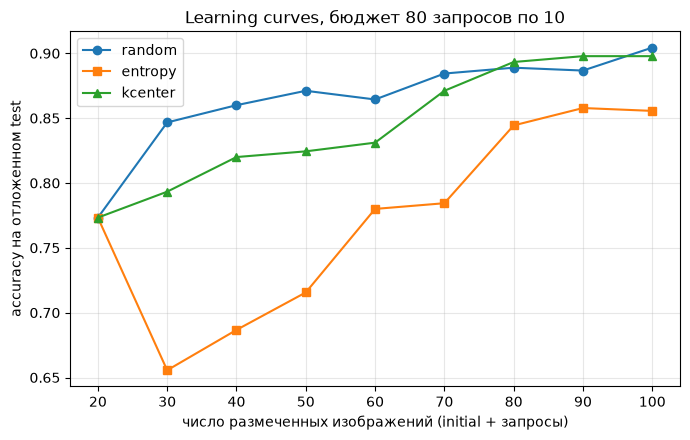

Бюджеты (запросов): [0, 10, 20, 30, 40, 50, 60, 70, 80]
random   [0.7733, 0.8467, 0.86, 0.8711, 0.8644, 0.8844, 0.8889, 0.8867, 0.9044]
entropy  [0.7733, 0.6556, 0.6867, 0.7156, 0.78, 0.7844, 0.8444, 0.8578, 0.8556]
kcenter  [0.7733, 0.7933, 0.82, 0.8244, 0.8311, 0.8711, 0.8933, 0.8978, 0.8978]
Сохранено: artifacts\lab8\learning_curves.json и learning_curves.png


In [7]:
# Кривые обучения при общем бюджете разметки
import matplotlib.pyplot as plt

BUDGETS = [p["n_queries"] for p in RUNS[STRATEGIES[0]]["trace"]]   # 0, 10, ..., BUDGET запросов
curves = {}
for s in STRATEGIES:
    tr = RUNS[s]["trace"]
    # Все стратегии должны иметь точки ровно на одних и тех же бюджетах
    assert [p["n_queries"] for p in tr] == BUDGETS
    curves[s] = {"n_queries": [p["n_queries"] for p in tr],
                 "n_labeled": [p["n_labeled"] for p in tr],
                 "test_acc": [round(p["test_acc"], 4) for p in tr]}

learning_curves = {
    "x_axis": "n_queries (число меток, запрошенных у oracle сверх initial)",
    "budgets": BUDGETS, "n_initial": int(len(initial_idx)),
    "batch_size": BATCH_SIZE, "n_rounds": N_ROUNDS, "total_budget": BUDGET,
    "test_size": int(len(test_idx)), "seed": SEED, "fast_dev_run": FAST_DEV_RUN,
    "source": "al_runs.json (trace функции run)",
    "curves": curves,
}
save_json("learning_curves.json", learning_curves)

fig, ax = plt.subplots(figsize=(7, 4.5))
for s, m in zip(STRATEGIES, ["o", "s", "^"]):
    ax.plot(curves[s]["n_labeled"], curves[s]["test_acc"], marker=m, label=s)
ax.set_xlabel("число размеченных изображений (initial + запросы)")
ax.set_ylabel("accuracy на отложенном test")
ax.set_title(f"Learning curves, бюджет {BUDGET} запросов по {BATCH_SIZE}")
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(ARTIFACTS / "learning_curves.png", dpi=120)
plt.show()

print("Бюджеты (запросов):", BUDGETS)
for s in STRATEGIES:
    print(f"{s:8s}", curves[s]["test_acc"])
print("Сохранено:", ARTIFACTS / "learning_curves.json", "и learning_curves.png")

### Задание 7. Интеграл по бюджету разметки

*Вес: 1 балл.*

**Постановка.** Этап «интеграл по бюджету разметки» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Проинтегрируйте кривые accuracy по числу полученных меток.
2. Сохраните и предъявите AUC и конечная accuracy из фактических кривых.

**Результат.** AUC и конечная accuracy из фактических кривых.

**Критерий принятия.** Задание считается принятым, если AUC и конечная accuracy из фактических кривых получены из фактических входов этого этапа и доступны для проверки.

**Задание 7. Интеграл по бюджету разметки**

**Что делали**: проинтегрировали каждую кривую методом трапеций по числу меток и разделили площадь на ширину интервала (80 меток).<br>
**Зачем**: оценить всю кривую одним числом: AUC_norm — средняя accuracy за весь бюджет, в отличие от конечной accuracy, которая показывает только последнюю точку.<br>
**Результат**: файл `budget_auc.json`. AUC_norm: random 0.868, k-center 0.846, entropy 0.767 (AUC_raw 69.41, 67.67, 61.39).

In [8]:
# Интеграл accuracy по бюджету разметки (AUC learning curve) и конечная accuracy
def curve_auc(n_labels, acc):
    # Метод трапеций по числу полученных меток
    x, y = np.asarray(n_labels, float), np.asarray(acc, float)
    area = float(np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2))
    return area, area / float(x[-1] - x[0])      # сырой интеграл и нормированный (средняя accuracy, 0..1)

budget_auc = {"method": "трапеции по n_labeled, нормировка на ширину интервала",
              "x_range": [curves[STRATEGIES[0]]["n_labeled"][0], curves[STRATEGIES[0]]["n_labeled"][-1]],
              "source": "learning_curves.json", "strategies": {}}
for s in STRATEGIES:
    area, auc_norm = curve_auc(curves[s]["n_labeled"], curves[s]["test_acc"])
    budget_auc["strategies"][s] = {"auc_raw": round(area, 4), "auc_norm": round(auc_norm, 4),
                                   "initial_acc": curves[s]["test_acc"][0],
                                   "final_acc": curves[s]["test_acc"][-1],
                                   "final_n_labeled": curves[s]["n_labeled"][-1]}
    # Нормированный AUC — среднее значение accuracy, поэтому лежит между её минимумом и максимумом
    assert min(curves[s]["test_acc"]) - 1e-9 <= auc_norm <= max(curves[s]["test_acc"]) + 1e-9

save_json("budget_auc.json", budget_auc)
print(f"{'стратегия':10s} {'AUC_raw':>9s} {'AUC_norm':>9s} {'acc@start':>10s} {'acc@end':>8s}")
for s, v in budget_auc["strategies"].items():
    print(f"{s:10s} {v['auc_raw']:9.2f} {v['auc_norm']:9.4f} {v['initial_acc']:10.4f} {v['final_acc']:8.4f}")
print("Сохранено:", ARTIFACTS / "budget_auc.json")

стратегия    AUC_raw  AUC_norm  acc@start  acc@end
random         69.41    0.8676     0.7733   0.9044
entropy        61.39    0.7674     0.7733   0.8556
kcenter        67.67    0.8458     0.7733   0.8978
Сохранено: artifacts\lab8\budget_auc.json


**Что такое интеграл по бюджету разметки (AUC learning curve)**

Интеграл кривой обучения — это **площадь под графиком** accuracy на test в зависимости от числа размеченных изображений. Чем выше кривая на всём протяжении, тем больше площадь.

**Как вычисляется.** Точки кривой $(n_0, a_0), (n_1, a_1), \dots, (n_K, a_K)$ — число меток и accuracy после каждого раунда. Соседние точки соединяются отрезками, и площадь считается **методом трапеций**:

$$\text{AUC}_{raw} = \sum_{k=1}^{K} (n_k - n_{k-1}) \cdot \frac{a_{k-1} + a_k}{2}$$

$$\text{AUC}_{norm} = \frac{\text{AUC}_{raw}}{n_K - n_0}$$

- **`auc_raw`** — сама площадь в единицах «метки × accuracy». У нас ширина интервала 80 меток (от 20 до 100), поэтому значение порядка 60–70; само по себе оно плохо интерпретируется.
- **`auc_norm`** — площадь, делённая на ширину интервала. Это **средняя accuracy за весь бюджет разметки**, лежит от 0 до 1 и напрямую сравнима между стратегиями.

**Для чего это нужно.** Конечная accuracy показывает только качество модели в последней точке, когда бюджет уже потрачен. AUC учитывает, **как быстро** стратегия набирает качество: если стратегия долго отстаёт и догоняет только в конце, конечная accuracy у неё может быть почти такой же, а AUC — заметно меньше. На практике разметку часто останавливают раньше плана, поэтому стратегия с большим AUC выгоднее: она даёт хорошую модель на любом шаге, а не только в конце. Поэтому для сравнения стратегий сохраняются оба показателя — AUC и конечная accuracy.

### Задание 8. Повторные случайные запросы

*Вес: 1 балл.*

**Постановка.** Этап «повторные случайные запросы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Повторите random с разными генераторами при неизменном train/test.
2. Сохраните и предъявите результаты random при различных seed.

**Результат.** результаты random при различных seed.

**Критерий принятия.** Задание считается принятым, если результаты random при различных seed получены из фактических входов этого этапа и доступны для проверки.

**Задание 8. Повторные случайные запросы**

**Что делали**: запустили random ещё 10 раз с seed 0…9 при тех же train/test/initial/pool и сравнили с ними основные запуски.<br>
**Зачем**: понять, какой разброс даёт обычное везение, и не делать выводы по одному запуску random.<br>
**Результат**: файл `random_seeds.json`. Random по 10 seed: AUC_norm 0.837 ± 0.013 (от 0.814 до 0.858), конечная accuracy 0.881 ± 0.015 (от 0.851 до 0.893). z по AUC: random с seed 42 +2.45 (нетипично удачный запуск), k-center +0.70, entropy −5.58.

In [9]:
# Повторные случайные запросы: random с разными генераторами при неизменных train/test/initial/pool
RANDOM_SEEDS = [0, 1] if FAST_DEV_RUN else [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
split_fingerprint = (tuple(train_idx), tuple(test_idx), tuple(initial_idx), tuple(pool_idx))

random_runs = {}
for sd in RANDOM_SEEDS:
    res = run("random", seed=sd)
    tr = res["trace"]
    assert [p["n_queries"] for p in tr] == BUDGETS            # те же бюджеты, что у основных кривых
    acc = [round(p["test_acc"], 4) for p in tr]
    area, auc_norm = curve_auc([p["n_labeled"] for p in tr], acc)
    random_runs[sd] = {"test_acc": acc, "auc_norm": round(auc_norm, 4), "final_acc": acc[-1],
                       "queried_idx": [i for p in tr for i in p.get("queried_idx", [])]}
# Разбиение не менялось, а разные генераторы дали разные запросы
assert split_fingerprint == (tuple(train_idx), tuple(test_idx), tuple(initial_idx), tuple(pool_idx))
assert len({tuple(r["queried_idx"]) for r in random_runs.values()}) == len(RANDOM_SEEDS)

aucs = np.array([r["auc_norm"] for r in random_runs.values()])
finals = np.array([r["final_acc"] for r in random_runs.values()])
acc_matrix = np.array([r["test_acc"] for r in random_runs.values()])
random_summary = {
    "auc_norm_mean": round(float(aucs.mean()), 4), "auc_norm_std": round(float(aucs.std(ddof=1)), 4),
    "final_acc_mean": round(float(finals.mean()), 4), "final_acc_std": round(float(finals.std(ddof=1)), 4),
    "curve_mean": np.round(acc_matrix.mean(0), 4).tolist(), "curve_std": np.round(acc_matrix.std(0, ddof=1), 4).tolist(),
}
# Где AL-стратегии относительно разброса random (в единицах std)
vs_random = {s: {"auc_norm": budget_auc["strategies"][s]["auc_norm"],
                 "z_vs_random": round((budget_auc["strategies"][s]["auc_norm"] - aucs.mean()) / aucs.std(ddof=1), 2),
                 "share_random_seeds_beaten": round(float((aucs < budget_auc["strategies"][s]["auc_norm"]).mean()), 2)}
             for s in STRATEGIES}

save_json("random_seeds.json", {"seeds": RANDOM_SEEDS, "budgets": BUDGETS,
                                "split_unchanged": True, "split_source": "split.json",
                                "runs": {str(k): v for k, v in random_runs.items()},
                                "summary": random_summary, "strategies_vs_random": vs_random})
for sd, r in random_runs.items():
    print(f"seed={sd}: AUC_norm={r['auc_norm']:.4f}  final_acc={r['final_acc']:.4f}")
print(f"random: AUC_norm = {random_summary['auc_norm_mean']:.4f} ± {random_summary['auc_norm_std']:.4f}, "
      f"final_acc = {random_summary['final_acc_mean']:.4f} ± {random_summary['final_acc_std']:.4f}")
for s, v in vs_random.items():
    print(f"{s:8s} AUC_norm={v['auc_norm']:.4f}  z={v['z_vs_random']:+.2f}  лучше {v['share_random_seeds_beaten']:.0%} random-seed")
print("Сохранено:", ARTIFACTS / "random_seeds.json")

seed=0: AUC_norm=0.8364  final_acc=0.8889
seed=1: AUC_norm=0.8583  final_acc=0.8933
seed=2: AUC_norm=0.8379  final_acc=0.8778
seed=3: AUC_norm=0.8310  final_acc=0.8867
seed=4: AUC_norm=0.8315  final_acc=0.8911
seed=5: AUC_norm=0.8419  final_acc=0.8933
seed=6: AUC_norm=0.8536  final_acc=0.8933
seed=7: AUC_norm=0.8135  final_acc=0.8511
seed=8: AUC_norm=0.8329  final_acc=0.8733
seed=9: AUC_norm=0.8336  final_acc=0.8622
random: AUC_norm = 0.8371 ± 0.0125, final_acc = 0.8811 ± 0.0148
random   AUC_norm=0.8676  z=+2.45  лучше 100% random-seed
entropy  AUC_norm=0.7674  z=-5.58  лучше 0% random-seed
kcenter  AUC_norm=0.8458  z=+0.70  лучше 80% random-seed
Сохранено: artifacts\lab8\random_seeds.json


| строка | AUC_norm | откуда | обучение в задании 8 |
|---|---|---|---|
| random | 0.8676 | основной запуск с seed 42 из задания 5 | нет |
| entropy | 0.7674 | запуск из задания 5 | нет |
| kcenter | 0.8458 | запуск из задания 5 | нет |

По 10 значениям считаются среднее и стандартное отклонение: `random: AUC_norm = 0.8371 ± 0.0125, final_acc = 0.8811 ± 0.0148`.

**AUC_norm** - это средняя accuracy модели за весь бюджет разметки. Берётся площадь под кривой accuracy и делится на ширину интервала, 80 меток (от 20 до 100).

**z** показывает, на сколько стандартных отклонений random AUC стратегии отличается от среднего random: (0.7674 − 0.8371) / 0.0125 ≈ −5.58 для entropy.

**«лучше N% random-seed»** показывает, скольких из 10 random-запусков стратегия обогнала по AUC. У k-center это 80%, то есть 8 из 10.

Стандартное отклонение показывает, насколько отдельные запуски random обычно отличаются от их среднего. Оно описывает разброс самих результатов.

95%-й доверительный интервал показывает, где с высокой надёжностью находится настоящее среднее значение random, а не отдельный запуск:

### Задание 9. Разбор ошибок отложенного теста

*Вес: 1 балл.*

**Постановка.** Этап «разбор ошибок отложенного теста» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните изображения и истинные/предсказанные классы ошибочных test-примеров.
2. Сохраните и предъявите artifacts/test_errors.json с неверно распознанными изображениями.

**Результат.** artifacts/test_errors.json с неверно распознанными изображениями.

**Критерий принятия.** Задание считается принятым, если artifacts/test_errors.json с неверно распознанными изображениями получены из фактических входов этого этапа и доступны для проверки.

**Задание 9. Разбор ошибок отложенного теста**

**Что делали**: взяли предсказания финальных моделей (100 меток) на 450 изображениях test, сохранили каждое ошибочное изображение в PNG с истинным и предсказанным классом и посчитали частые путаницы.<br>
**Зачем**: понять не только сколько ошибок, но и какие именно ошибки делает каждая стратегия.<br>
**Результат**: файлы `test_errors.json`, `test_errors_grid.png` и 154 PNG в `images/test_errors/`. Ошибок: random 43, k-center 46, entropy 65. У entropy 46 из 65 ошибок — ответ «8». У k-center 9 ошибок на нулях: за 80 запросов он не выбрал ни одного нуля. 8 изображений ошибочны у всех трёх стратегий.

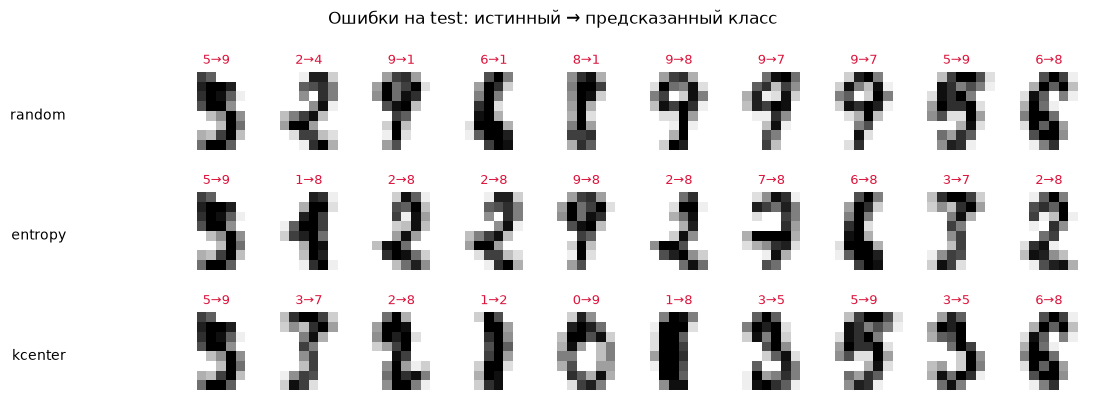

random   ошибок= 43  acc=0.9044  частые пары (true→pred): [(1, 9, 7), (1, 2, 6), (5, 9, 4), (8, 1, 3), (9, 8, 2)]
entropy  ошибок= 65  acc=0.8556  частые пары (true→pred): [(1, 8, 18), (9, 8, 16), (2, 8, 5), (9, 7, 3), (3, 8, 3)]
kcenter  ошибок= 46  acc=0.8978  частые пары (true→pred): [(5, 9, 6), (1, 8, 4), (1, 2, 3), (0, 9, 3), (0, 6, 3)]
Общих ошибок у всех стратегий: 8
Сохранено: artifacts\lab8\test_errors.json | PNG: artifacts\lab8\images\test_errors


In [10]:
# Разбор ошибок отложенного теста: финальные модели (после всего бюджета) каждой стратегии
from collections import Counter

ERR_DIR = LAB_IMAGES / "test_errors"
y_test = y_all[test_idx]
test_errors = {"source": "final_test_pred из al_runs.json (модель после последнего раунда)",
               "n_test": int(len(test_idx)), "image_dir": str(ERR_DIR), "strategies": {}}

for s in STRATEGIES:
    pred = np.asarray(RUNS[s]["final_test_pred"])
    assert len(pred) == len(test_idx)
    wrong = np.flatnonzero(pred != y_test)
    (ERR_DIR / s).mkdir(parents=True, exist_ok=True)
    errors = []
    for k in wrong:
        i = int(test_idx[k])
        path = ERR_DIR / s / f"test{i:04d}_true{y_test[k]}_pred{pred[k]}.png"
        # 8x8 изображение увеличиваем до 64x64 без сглаживания, чтобы было видно пиксели
        plt.imsave(path, np.kron(IMAGES_ALL[i], np.ones((8, 8))), cmap="gray_r", vmin=0, vmax=16)
        errors.append({"idx": i, "true": int(y_test[k]), "pred": int(pred[k]),
                       "image_path": str(path), "pixels_8x8": IMAGES_ALL[i].astype(int).tolist()})
    pairs = Counter((e["true"], e["pred"]) for e in errors).most_common(5)
    test_errors["strategies"][s] = {
        "n_errors": len(errors), "test_acc": round(1 - len(errors) / len(test_idx), 4),
        "top_confusions": [{"true": t, "pred": p, "count": c} for (t, p), c in pairs],
        "errors": errors,
    }
    # accuracy из ошибок совпадает с последней точкой кривой
    assert abs(test_errors["strategies"][s]["test_acc"] - curves[s]["test_acc"][-1]) < 1e-3

# Ошибки, общие для всех стратегий: «трудные» изображения, а не следствие выбора запросов
common = set.intersection(*[{e["idx"] for e in test_errors["strategies"][s]["errors"]} for s in STRATEGIES])
test_errors["common_errors_idx"] = sorted(common)
save_json("test_errors.json", test_errors)

# Наглядная сетка: первые ошибки каждой стратегии
N_SHOW = 10
fig, axes = plt.subplots(len(STRATEGIES), N_SHOW, figsize=(N_SHOW * 1.1, len(STRATEGIES) * 1.4))
for row, s in zip(axes, STRATEGIES):
    errs = test_errors["strategies"][s]["errors"][:N_SHOW]
    for j, ax in enumerate(row):
        ax.axis("off")
        if j < len(errs):
            e = errs[j]
            ax.imshow(IMAGES_ALL[e["idx"]], cmap="gray_r", vmin=0, vmax=16)
            ax.set_title(f"{e['true']}→{e['pred']}", fontsize=9, color="crimson")
    row[0].text(-12, 4, s, fontsize=10, va="center", ha="right")
fig.suptitle("Ошибки на test: истинный → предсказанный класс")
fig.tight_layout(); fig.savefig(ARTIFACTS / "test_errors_grid.png", dpi=120)
plt.show()

for s in STRATEGIES:
    v = test_errors["strategies"][s]
    print(f"{s:8s} ошибок={v['n_errors']:3d}  acc={v['test_acc']:.4f}  частые пары (true→pred):",
          [(c["true"], c["pred"], c["count"]) for c in v["top_confusions"]])
print("Общих ошибок у всех стратегий:", len(common))
print("Сохранено:", ARTIFACTS / "test_errors.json", "| PNG:", ERR_DIR)

### Задание 10. Сводка сравнительного эксперимента

*Вес: 1 балл.*

**Постановка.** Этап «сводка сравнительного эксперимента» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сопоставьте AUC и конечную точность по трём стратегиям.
2. Сохраните и предъявите artifacts/comparison.json.

**Результат.** artifacts/comparison.json.

**Критерий принятия.** Задание считается принятым, если artifacts/comparison.json получены из фактических входов этого этапа и доступны для проверки.

**Задание 10. Сводка сравнительного эксперимента**

**Что делали**: свели в одну таблицу AUC, конечную accuracy, число ошибок и сравнение со средним random по 10 seed, построили кривые на фоне разброса random.<br>
**Зачем**: получить итоговое сравнение трёх стратегий при равном бюджете.<br>
**Результат**: файлы `comparison.json` и `comparison.png`. Порядок по AUC и по конечной accuracy: random > k-center > entropy. Относительно среднего random: k-center +0.009 (в пределах разброса), entropy −0.070 (значимо хуже).

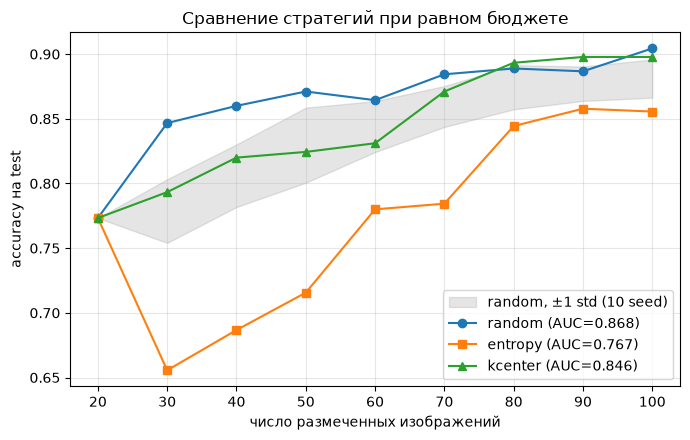

стратегия   AUC_norm  final_acc  ΔAUC vs rnd      z  ошибок
random        0.8676     0.9044      +0.0305  +2.45      43
kcenter       0.8458     0.8978      +0.0087  +0.70      46
entropy       0.7674     0.8556      -0.0697  -5.58      65
При бюджете 80 запросов лучший AUC у random (0.8676); random по 10 seed: 0.8371 ± 0.0125. Конечная accuracy: random 0.9044, kcenter 0.8978, entropy 0.8556.
Сохранено: artifacts\lab8\comparison.json и comparison.png


In [11]:
# Сводка сравнительного эксперимента: AUC и конечная accuracy трёх стратегий
rows = {}
for s in STRATEGIES:
    b = budget_auc["strategies"][s]
    rows[s] = {"auc_norm": b["auc_norm"], "auc_raw": b["auc_raw"],
               "initial_acc": b["initial_acc"], "final_acc": b["final_acc"],
               "gain_acc": round(b["final_acc"] - b["initial_acc"], 4),
               "n_test_errors": test_errors["strategies"][s]["n_errors"],
               "z_auc_vs_random_seeds": vs_random[s]["z_vs_random"],
               "share_random_seeds_beaten_auc": vs_random[s]["share_random_seeds_beaten"],
               "delta_auc_vs_random_mean": round(b["auc_norm"] - random_summary["auc_norm_mean"], 4),
               "delta_final_vs_random_mean": round(b["final_acc"] - random_summary["final_acc_mean"], 4)}
    # Значения в сводке совпадают с фактическими кривыми
    assert rows[s]["final_acc"] == curves[s]["test_acc"][-1]

rank_auc = sorted(STRATEGIES, key=lambda s: -rows[s]["auc_norm"])
rank_final = sorted(STRATEGIES, key=lambda s: -rows[s]["final_acc"])
best = rank_auc[0]
comparison = {
    "setup": {"dataset": "sklearn load_digits", "n_initial": int(len(initial_idx)), "n_pool": int(len(pool_idx)),
              "n_test": int(len(test_idx)), "batch_size": BATCH_SIZE, "n_rounds": N_ROUNDS,
              "total_budget": BUDGET, "model": "LogisticRegression", "seed": SEED, "fast_dev_run": FAST_DEV_RUN},
    "metrics": rows,
    "random_over_seeds": {"seeds": RANDOM_SEEDS, **{k: v for k, v in random_summary.items() if not k.startswith("curve")}},
    "ranking_by_auc": rank_auc, "ranking_by_final_acc": rank_final,
    "sources": ["learning_curves.json", "budget_auc.json", "random_seeds.json", "test_errors.json"],
    "conclusion": (f"При бюджете {BUDGET} запросов лучший AUC у {best} ({rows[best]['auc_norm']:.4f}); "
                   f"random по {len(RANDOM_SEEDS)} seed: {random_summary['auc_norm_mean']:.4f} ± {random_summary['auc_norm_std']:.4f}. "
                   f"Конечная accuracy: " + ", ".join(f"{s} {rows[s]['final_acc']:.4f}" for s in rank_final) + "."),
}
save_json("comparison.json", comparison)

# График: кривые трёх стратегий на фоне разброса random по seed
x = curves[STRATEGIES[0]]["n_labeled"]
m, sd = np.array(random_summary["curve_mean"]), np.array(random_summary["curve_std"])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.fill_between(x, m - sd, m + sd, alpha=0.2, color="gray", label=f"random, ±1 std ({len(RANDOM_SEEDS)} seed)")
for s, mk in zip(STRATEGIES, ["o", "s", "^"]):
    ax.plot(x, curves[s]["test_acc"], marker=mk, label=f"{s} (AUC={rows[s]['auc_norm']:.3f})")
ax.set_xlabel("число размеченных изображений"); ax.set_ylabel("accuracy на test")
ax.set_title("Сравнение стратегий при равном бюджете"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(ARTIFACTS / "comparison.png", dpi=120)
plt.show()

print(f"{'стратегия':10s} {'AUC_norm':>9s} {'final_acc':>10s} {'ΔAUC vs rnd':>12s} {'z':>6s} {'ошибок':>7s}")
for s in rank_auc:
    r = rows[s]
    print(f"{s:10s} {r['auc_norm']:9.4f} {r['final_acc']:10.4f} {r['delta_auc_vs_random_mean']:+12.4f} "
          f"{r['z_auc_vs_random_seeds']:+6.2f} {r['n_test_errors']:7d}")
print(comparison["conclusion"])
print("Сохранено:", ARTIFACTS / "comparison.json", "и comparison.png")

**Как читать график и таблицу сводки**

**Серая полоса на графике** — диапазон, в котором обычно лежит случайный выбор: среднее accuracy random по 10 seed ± 1 стандартное отклонение в каждой точке бюджета. Всё, что попадает внутрь полосы, не отличается от random больше, чем отличаются друг от друга случайные запуски, то есть объясняется везением. Кривая выше полосы — стратегия заметно лучше random, ниже — заметно хуже. Синяя линия random — один запуск с seed 42; то, что она почти всё время выше полосы, означает, что этот запуск оказался необычно удачным.

**ΔAUC vs rnd** — показывает, насколько AUC_norm стратегии выше или ниже среднего AUC_norm случайного выбора по 10 seed.

**z** — показывает, на сколько стандартных отклонений random стратегия отличается от среднего random.

$$z = \frac{\text{AUC}_{\text{стратегии}} - \overline{\text{AUC}}_{\text{random}}}{\sigma_{\text{random}}}$$


| z | интерпретация |
|---|---|
| $\lvert z\rvert < 1$ | в пределах шума, отличие от random не установлено |
| $1 \le \lvert z\rvert < 2$ | намёк на отличие, но не уверенный |
| $z \ge 2$ | заметно лучше random, вряд ли это везение |
| $z \le -2$ | заметно хуже random |

Поэтому стратегии корректно сравнивать не с одним запуском random, а со средним по seed: ΔAUC говорит, насколько стратегия лучше, а z — можно ли этому выигрышу доверять.

### Задание 11. Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

**Гипотеза:** на более разнородных цифрах k-center теряет свой выигрыш над random, потому что тратит бюджет на нетипичные картинки.

**Логика:** k-center выбирает картинки, самые далёкие от уже размеченных по пикселям. В `load_digits` почерк довольно однородный, а в MNIST больше авторов, толщин и наклонов. Поэтому на MNIST самыми далёкими чаще окажутся выбросы, а не полезные примеры.

**Два проверяемых предсказания:**
- **P1:** ΔAUC k-center относительно random на MNIST меньше, чем на `load_digits`.
- **P2:** на MNIST k-center выбирает более нетипичные картинки, чем random. Нетипичность измеряется расстоянием картинки до центра её класса (берутся все картинки класса и усредняются их пиксели. Затем считается евклидовое расстояние картинки до центра её класса).

| | `load_digits` | MNIST |
|---|---|---|
| изображений | 1797 | 70 000 |
| исходный размер | 8×8 | 28×28 |
| авторов | 43 | около 500 |

`load_digits` использовался на протяжении всей лабораторной

| | MNIST |
|---|---|
| initial | 20 картинок, по 2 каждой цифры |
| запросов | 80 (8 раундов по 10) |
| итоговая обучающая выборка | **100 картинок** |
| pool, из которого выбирали | 1500 картинок |
| test для проверки | 1000 картинок |

**Задание 11. Творческое мини-исследование**

**Что делали**: повторили эксперимент на MNIST, приведённом к формату `load_digits` 8×8: initial 20, pool 1500, test 1000 из MNIST t10k, random с 5 seed. Измерили нетипичность изображений, выбранных k-center и random.<br>
**Зачем**: проверить, переносится ли выигрыш k-center на более разнородные цифры.<br>
**Результат**: файлы `bonus.md`, `bonus_result.json`, `bonus_kcenter_picks.png`. ΔAUC k-center относительно random: +0.009 на `load_digits` → −0.036 на MNIST. Нетипичность на MNIST: k-center 2.87 против 2.15 у random. Конечная accuracy на MNIST: random 0.735, k-center 0.718, entropy 0.699. P1 и P2 выполнены.

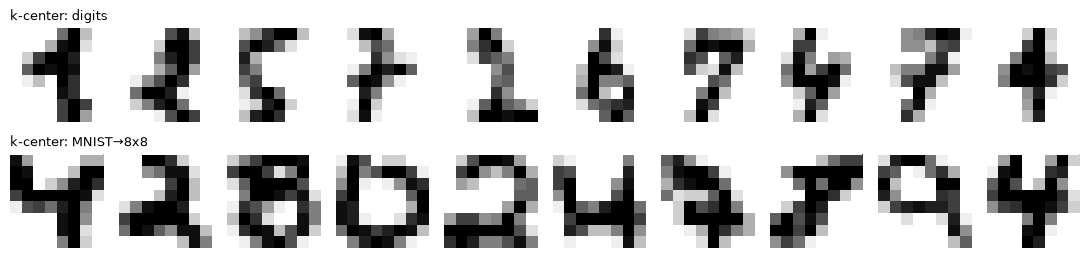

{
 "delta_auc_vs_random": {
  "digits": {
   "entropy": -0.0697,
   "kcenter": 0.0087
  },
  "mnist": {
   "entropy": -0.0388,
   "kcenter": -0.0357
  }
 },
 "atypicality": {
  "digits": {
   "kcenter": 2.125659465789795,
   "random": 1.6731446981430054
  },
  "mnist": {
   "kcenter": 2.8652422428131104,
   "random": 2.149329423904419
  }
 },
 "P1": true,
 "P2": true,
 "verdict": "подтверждается"
}
Сохранено: artifacts\lab8\bonus.md и bonus_result.json


In [12]:
# Творческое мини-исследование: переносится ли выигрыш AL-стратегий на реальные цифры другого источника
# ГИПОТЕЗА (сформулирована до запуска, из устройства методов, а не по отложенному test):
#   k-center работает в сыром пиксельном пространстве и выбирает самые удалённые изображения.
#   На load_digits почерк однородный (43 автора, одна процедура сбора), а в MNIST — сотни авторов,
#   разная толщина и наклон штрихов. Поэтому на MNIST k-center будет тратить бюджет на нетипичные
#   изображения (выбросы), и его выигрыш над random окажется меньше, чем на load_digits.
# Проверяемые предсказания:
#   P1: ΔAUC(k-center − random) на MNIST < ΔAUC(k-center − random) на load_digits;
#   P2: изображения, выбранные k-center на MNIST, дальше от центроида своего класса, чем выбранные random.
# Отложенный test load_digits здесь не используется: оценка — на отдельной части MNIST t10k.
import gzip

def read_idx(path):
    data = path.read_bytes()
    if data[:2] == b"\x1f\x8b":
        data = gzip.decompress(data)
    ndim = data[3]
    shape = [int.from_bytes(data[4 + 4 * k: 8 + 4 * k], "big") for k in range(ndim)]
    return np.frombuffer(data, dtype=np.uint8, offset=4 + 4 * ndim).reshape(shape)

from PIL import Image

def mnist_to_digits_format(imgs28):
    # Та же процедура, что у load_digits (UCI optdigits): цифра обрезается по рамке и масштабируется
    # в бинарную картинку 32x32 (с сохранением пропорций), затем блоки 4x4 -> число «включённых»
    # пикселей (0..16) -> 8x8.
    out = np.zeros((len(imgs28), 8, 8))
    for n, img in enumerate(imgs28):
        rows, cols = np.flatnonzero(img.max(1) > 127), np.flatnonzero(img.max(0) > 127)
        crop = img[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]
        h, w = crop.shape; scale = 32 / max(h, w)
        nh, nw = max(1, round(h * scale)), max(1, round(w * scale))
        resized = np.asarray(Image.fromarray(crop).resize((nw, nh), Image.BILINEAR))
        canvas = np.zeros((32, 32), dtype=bool)
        top, left = (32 - nh) // 2, (32 - nw) // 2
        canvas[top:top + nh, left:left + nw] = resized > 127
        out[n] = canvas.reshape(8, 4, 8, 4).sum(axis=(1, 3))
    return out

MNIST_RAW = DATA_ROOT / "MNIST" / "raw"
mn_tr_img = read_idx(MNIST_RAW / "train-images-idx3-ubyte"); mn_tr_y = read_idx(MNIST_RAW / "train-labels-idx1-ubyte")
mn_te_img = read_idx(MNIST_RAW / "t10k-images-idx3-ubyte");  mn_te_y = read_idx(MNIST_RAW / "t10k-labels-idx1-ubyte")

N_MN_POOL, N_MN_TEST = (300, 300) if FAST_DEV_RUN else (1500, 1000)
rng_mn = np.random.default_rng(SEED)
tr_sel = rng_mn.choice(len(mn_tr_y), size=N_MN_POOL + len(CLASSES) * N_INIT_PER_CLASS, replace=False)
te_sel = rng_mn.choice(len(mn_te_y), size=N_MN_TEST, replace=False)
MN_IMAGES = np.concatenate([mnist_to_digits_format(mn_tr_img[tr_sel]), mnist_to_digits_format(mn_te_img[te_sel])])
MN_X = (MN_IMAGES.reshape(len(MN_IMAGES), -1) / 16.0).astype(np.float32)
MN_y = np.concatenate([mn_tr_y[tr_sel], mn_te_y[te_sel]]).astype(int)
mn_train = np.arange(len(tr_sel)); mn_test = np.arange(len(tr_sel), len(MN_y))
mn_initial = np.sort(np.concatenate([rng_mn.choice(mn_train[MN_y[mn_train] == c], N_INIT_PER_CLASS, replace=False)
                                     for c in CLASSES]))
mn_pool = np.setdiff1d(mn_train, mn_initial)
assert MN_X.shape[1] == X_all.shape[1] and MN_IMAGES.max() <= 16

# Обобщённая версия run(): те же стратегии, oracle, модель и бюджет, но на произвольных данных
def kcenter_on(X, pool, k, labeled):
    Xp = X[pool]
    min_dist = np.min(np.linalg.norm(Xp[:, None, :] - X[labeled][None, :, :], axis=2), axis=1)
    chosen = []
    for _ in range(k):
        j = int(np.argmax(min_dist)); chosen.append(pool[j])
        min_dist = np.minimum(min_dist, np.linalg.norm(Xp - Xp[j], axis=1)); min_dist[j] = -np.inf
    return np.array(chosen)

def run_on(X, y, init, pool0, test, strategy, seed=SEED):
    rng = np.random.default_rng(seed)
    oracle = SimulatedOracle(y, np.concatenate([init, pool0]))
    labeled, y_lab, pool = init.copy(), oracle.label(init, "initial", 0), pool0.copy()
    acc, n_lab, queried = [], [], []
    for r in range(N_ROUNDS + 1):
        model = make_model().fit(X[labeled], y_lab)
        acc.append(float(accuracy_score(y[test], model.predict(X[test])))); n_lab.append(int(len(labeled)))
        if r == N_ROUNDS:
            break
        if strategy == "random":
            sel = rng.choice(pool, BATCH_SIZE, replace=False)
        elif strategy == "entropy":
            sel = pool[np.argsort(-entropy_scores(model.predict_proba(X[pool])), kind="stable")[:BATCH_SIZE]]
        else:
            sel = kcenter_on(X, pool, BATCH_SIZE, labeled)
        new = oracle.label(sel, strategy, r + 1)
        labeled, y_lab, pool = np.concatenate([labeled, sel]), np.concatenate([y_lab, new]), np.setdiff1d(pool, sel)
        queried += sel.tolist()
    return {"n_labeled": n_lab, "test_acc": acc, "auc_norm": curve_auc(n_lab, acc)[1], "queried_idx": queried}

BONUS_SEEDS = RANDOM_SEEDS[:5]
mn_runs = {s: run_on(MN_X, MN_y, mn_initial, mn_pool, mn_test, s) for s in ["entropy", "kcenter"]}
mn_random = [run_on(MN_X, MN_y, mn_initial, mn_pool, mn_test, "random", seed=sd) for sd in BONUS_SEEDS]
mn_rnd_auc = np.array([r["auc_norm"] for r in mn_random])

# P2: нетипичность выбранных изображений = расстояние до центроида своего класса (центроиды по всему pool;
# метки pool используются только для этого апостериорного анализа, не для выбора)
def atypicality(X, y, base_idx, picked):
    cent = {c: X[base_idx][y[base_idx] == c].mean(0) for c in CLASSES}
    return float(np.mean([np.linalg.norm(X[i] - cent[y[i]]) for i in picked]))

dg_rnd_q = random_runs[BONUS_SEEDS[0]]["queried_idx"]
dg_kc_q = [i for p in RUNS["kcenter"]["trace"] for i in p.get("queried_idx", [])]
dg_pool_lab = np.concatenate([initial_idx, pool_idx]); mn_pool_lab = np.concatenate([mn_initial, mn_pool])
atyp = {"digits": {"kcenter": atypicality(X_all, y_all, dg_pool_lab, dg_kc_q),
                   "random": atypicality(X_all, y_all, dg_pool_lab, dg_rnd_q)},
        "mnist": {"kcenter": atypicality(MN_X, MN_y, mn_pool_lab, mn_runs["kcenter"]["queried_idx"]),
                  "random": atypicality(MN_X, MN_y, mn_pool_lab, mn_random[0]["queried_idx"])}}

delta = {"digits": {s: round(budget_auc["strategies"][s]["auc_norm"] - random_summary["auc_norm_mean"], 4) for s in ["entropy", "kcenter"]},
         "mnist": {s: round(mn_runs[s]["auc_norm"] - float(mn_rnd_auc.mean()), 4) for s in ["entropy", "kcenter"]}}
P1 = delta["mnist"]["kcenter"] < delta["digits"]["kcenter"]
P2 = atyp["mnist"]["kcenter"] > atyp["mnist"]["random"]

# Изображения: первые запросы k-center на обоих наборах
fig, axes = plt.subplots(2, 10, figsize=(11, 2.8))
for row, (name, imgs, q) in zip(axes, [("digits", IMAGES_ALL, dg_kc_q), ("MNIST→8x8", MN_IMAGES, mn_runs["kcenter"]["queried_idx"])]):
    for ax, i in zip(row, q[:10]):
        ax.imshow(imgs[i], cmap="gray_r", vmin=0, vmax=16); ax.axis("off")
    row[0].set_title(f"k-center: {name}", fontsize=9, loc="left")
fig.tight_layout(); fig.savefig(ARTIFACTS / "bonus_kcenter_picks.png", dpi=120); plt.show()

mn_rnd_final = float(np.mean([r["test_acc"][-1] for r in mn_random]))
bonus_result = {
    "hypothesis": "выигрыш k-center над random меньше на MNIST, т.к. k-center выбирает нетипичные изображения",
    "mnist_setup": {"n_initial": int(len(mn_initial)), "n_pool": int(len(mn_pool)), "n_eval": int(len(mn_test)),
                    "eval_source": "MNIST t10k (не test load_digits)", "random_seeds": BONUS_SEEDS},
    "auc_norm": {
        "digits": {**{s: budget_auc["strategies"][s]["auc_norm"] for s in STRATEGIES},
                   "random_mean": random_summary["auc_norm_mean"]},
        "mnist": {**{s: round(mn_runs[s]["auc_norm"], 4) for s in mn_runs},
                  "random_mean": round(float(mn_rnd_auc.mean()), 4), "random_std": round(float(mn_rnd_auc.std(ddof=1)), 4)},
    },
    "final_acc_mnist": {**{s: round(mn_runs[s]["test_acc"][-1], 4) for s in mn_runs}, "random_mean": round(mn_rnd_final, 4)},
    "delta_auc_vs_random": delta, "atypicality": atyp, "P1_confirmed": bool(P1), "P2_confirmed": bool(P2),
    "mnist_curves": {**{s: mn_runs[s]["test_acc"] for s in mn_runs},
                     "random_mean": np.mean([r["test_acc"] for r in mn_random], 0).round(4).tolist()},
}
save_json("bonus_result.json", bonus_result)

verdict = "подтверждается" if P1 and P2 else ("не подтверждается" if not P1 and not P2 else "подтверждается частично")
bonus_md = f"""# Творческое мини-исследование: перенос выигрыша active learning на цифры другого источника

## Гипотеза
k-center в сыром пиксельном пространстве выбирает самые удалённые от размеченного множества изображения.
В `load_digits` почерк однородный, а в MNIST — сотни авторов, разная толщина и наклон штрихов.
**Гипотеза:** на MNIST k-center тратит бюджет на нетипичные изображения, поэтому его выигрыш над random меньше, чем на `load_digits`.

Гипотеза сформулирована до запуска из устройства метода; отложенный test `load_digits` для её выбора не использовался.

- **P1:** ΔAUC(k-center − random) на MNIST < ΔAUC на load_digits.
- **P2:** на MNIST изображения, выбранные k-center, дальше от центроида своего класса, чем выбранные random.

## Протокол
- Дополнительные реальные входы: MNIST (`{MNIST_RAW}`), приведённые к формату `load_digits` той же процедурой (бинаризация, 32×32, блоки 4×4 → 8×8, значения 0..16).
- Случайная подвыборка (seed={SEED}): initial {len(mn_initial)} (по {N_INIT_PER_CLASS} на класс), pool {len(mn_pool)} из MNIST train; оценка — {len(mn_test)} изображений MNIST t10k.
- Те же модель (`LogisticRegression`), oracle, бюджет ({N_ROUNDS} раундов × {BATCH_SIZE} = {BUDGET} запросов) и стратегии, что в основном эксперименте; random — {len(BONUS_SEEDS)} seed.
- Нетипичность = средняя евклидова дистанция выбранного изображения до центроида своего класса в pool (метки используются только апостериорно).
- Результаты: `bonus_result.json`, изображения запросов: `bonus_kcenter_picks.png`.

## Наблюдения
| набор | AUC entropy | AUC k-center | AUC random (среднее) | ΔAUC entropy | ΔAUC k-center |
|---|---|---|---|---|---|
| load_digits | {budget_auc['strategies']['entropy']['auc_norm']:.4f} | {budget_auc['strategies']['kcenter']['auc_norm']:.4f} | {random_summary['auc_norm_mean']:.4f} ± {random_summary['auc_norm_std']:.4f} | {delta['digits']['entropy']:+.4f} | {delta['digits']['kcenter']:+.4f} |
| MNIST→8×8 | {mn_runs['entropy']['auc_norm']:.4f} | {mn_runs['kcenter']['auc_norm']:.4f} | {mn_rnd_auc.mean():.4f} ± {mn_rnd_auc.std(ddof=1):.4f} | {delta['mnist']['entropy']:+.4f} | {delta['mnist']['kcenter']:+.4f} |

| набор | нетипичность k-center | нетипичность random |
|---|---|---|
| load_digits | {atyp['digits']['kcenter']:.3f} | {atyp['digits']['random']:.3f} |
| MNIST→8×8 | {atyp['mnist']['kcenter']:.3f} | {atyp['mnist']['random']:.3f} |

- P1 {'выполнено' if P1 else 'не выполнено'}: ΔAUC k-center {delta['digits']['kcenter']:+.4f} (digits) → {delta['mnist']['kcenter']:+.4f} (MNIST).
- P2 {'выполнено' if P2 else 'не выполнено'}: нетипичность k-center {atyp['mnist']['kcenter']:.3f} против {atyp['mnist']['random']:.3f} у random.
- Конечная accuracy на MNIST: entropy {mn_runs['entropy']['test_acc'][-1]:.4f}, k-center {mn_runs['kcenter']['test_acc'][-1]:.4f}, random {mn_rnd_final:.4f}.

## Вывод
Гипотеза **{verdict}**. Абсолютные значения на MNIST ниже, чем на `load_digits`, потому что MNIST разнообразнее, а модель и бюджет те же.
k-center оптимизирует покрытие пиксельного пространства, а не информативность для классификатора:
чем больше в pool нетипичных изображений, тем большую часть бюджета он отдаёт им. Для разнородных данных k-center стоит
считать в пространстве признаков модели (embeddings), а не в сырых пикселях. Ограничения: одна подвыборка MNIST, {len(BONUS_SEEDS)} seed для random,
один прогон детерминированных стратегий.
"""
(ARTIFACTS / "bonus.md").write_text(bonus_md, encoding="utf-8")
print(json.dumps({"delta_auc_vs_random": delta, "atypicality": atyp, "P1": bool(P1), "P2": bool(P2), "verdict": verdict},
                 ensure_ascii=False, indent=1))
print("Сохранено:", ARTIFACTS / "bonus.md", "и bonus_result.json")

`atypicality` — среднее расстояние выбранных картинок до центра их класса в пространстве пикселей.

На MNIST проверялись все три стратегии, причём заново: модели с `load_digits` туда не переносились.

| стратегия | сколько запусков на MNIST | seed |
|---|---|---|
| entropy | 1 | 42 |
| k-center | 1 | 42 |
| random | 5 | 0, 1, 2, 3, 4 |

$$\Delta\text{AUC} = \text{AUC}_{\text{стратегии}} - \text{среднее AUC}_{\text{random на том же наборе}}$$

| набор | стратегия | AUC_norm стратегии | среднее AUC_norm random | ΔAUC |
|---|---|---|---|---|
| `digits` | entropy | 0.7674 | 0.8371 | **−0.0697** |
| `digits` | k-center | 0.8458 | 0.8371 | **+0.0087** |
| `mnist` | entropy | 0.6106 | 0.6494 | **−0.0388** |
| `mnist` | k-center | 0.6137 | 0.6494 | **−0.0357** |

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

**Постановка.** `sklearn.datasets.load_digits`: 1797 изображений 8×8, 10 классов. Стратифицированный отложенный test — 450 изображений (43–46 на класс), отделён до выбора стратегий (`holdout_split.json`). Initial — 20 изображений (по 2 на класс), pool — 1327, бюджет — 8 раундов × 10 = 80 запросов к oracle (`split.json`). Классификатор — `LogisticRegression(max_iter=2000)`, переобучается с нуля после каждого раунда. Все числа ниже — из полного запуска (`FAST_DEV_RUN=False`); результаты FAST_DEV_RUN в выводы не входят.

**Сравнение на отложенной выборке** (`comparison.json`, `random_seeds.json`):

| стратегия | AUC_norm | ΔAUC vs random | z (AUC) | final accuracy | ошибок на test |
|---|---|---|---|---|---|
| random, 10 seed (эталон) | 0,837 ± 0,013 | 0 | 0 | 0,881 ± 0,015 | — |
| random, seed 42 | 0,868 | +0,031 | +2,45 | 0,904 | 43 |
| k-center | 0,846 | +0,009 | +0,70 | 0,898 | 46 |
| entropy | 0,767 | −0,070 | −5,58 | 0,856 | 65 |

- **Entropy значимо хуже random** и по AUC (z = −5,6, хуже всех 10 random-запусков), и по конечной accuracy (≈ −1,7 std). Главный вклад даёт первый раунд: accuracy падает с 0,773 до 0,656 и дальше лишь догоняет. Разница между z по AUC и по final accuracy показывает, что AUC фиксирует потерю качества на раннем бюджете, которую конечная точка уже «забывает».
- **k-center на уровне random:** выше среднего random по AUC (+0,009, лучше 8 из 10 seed) и по final accuracy (+0,017, ≈ +1,1 std), но z = +0,7 — в пределах случайного разброса; преимущество не установлено.
- **Основной запуск random (seed 42) — нетипично удачный** (z = +2,45, лучше всех 10 повторов). Сравнение с одним запуском random дало бы ложный вывод «k-center хуже random»; корректный ориентир — среднее по seed.
- Итог: при холодном старте с 20 меток и бюджете 80 ни одна «умная» стратегия не дала надёжного выигрыша над random; uncertainty sampling на слабой модели проигрывает.

**Разбор ошибок** (`test_errors.json`, PNG в `images/test_errors/`, сетка `test_errors_grid.png`):
- **entropy — смещение к классу 8.** 46 из 65 ошибок — предсказание «8»; чаще всего путаются 1→8 (18) и 9→8 (16). Причина видна в запросах (`al_runs.json`): в первом batch 9 из 10 изображений — восьмёрки (`query_selection.json`), за весь бюджет — 17 восьмёрок из 80 при ожидаемых ≈ 8. Обучающая выборка перекошена, и модель «видит» 8 в похожих по штрихам 1 и 9.
- **k-center — пропущенный класс.** За 80 запросов k-center **ни разу не выбрал 0**: нули в pool компактны и близки к уже размеченным, поэтому не бывают «самыми удалёнными». В обучении остаются только 2 нуля из initial, и на 0 приходится 9 из 46 ошибок (0→9, 0→6 по 3). Это иллюстрация того, что покрытие пространства признаков не гарантирует покрытия классов.
- **random** ошибается на визуально похожих парах без перекоса: 1→9 (7), 1→2 (6), 5→9 (4); класс 1 — самый трудный (16 из 43 ошибок).
- **8 изображений test ошибочны у всех трёх стратегий** (`common_errors_idx`) — это трудные примеры, которые не зависят от способа отбора.

**Ограничения выборки и эксперимента.**
- Test — 450 изображений: одно изображение = 0,22 п.п., стандартная ошибка accuracy ≈ 1,5 п.п. Разницы порядка 0,5–1 п.п. (random vs k-center в конце) этим тестом не различимы.
- Один набор initial (seed 42). Entropy и k-center детерминированы при фиксированном initial, поэтому их разброс не измерен: повторялся только random. Вывод про k-center ≈ random требует повторов с разными initial.
- `load_digits` — маленькие (8×8), чистые и сбалансированные данные одного источника; одна простая модель; oracle без шума. В реальной разметке есть дисбаланс классов и ошибки разметчика.
- Бюджет мал (100 меток из 1347): выводы относятся к режиму холодного старта; при большем бюджете uncertainty sampling может стать выгодным.
- Бонус (`bonus.md`) показывает, что и выигрыш k-center не переносится на более разнородные цифры MNIST (ΔAUC +0,009 → −0,036), но это одна подвыборка MNIST и 5 seed random.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.

In [13]:
# Конфигурация запуска, версии зависимостей и перечень артефактов
import hashlib, platform, sys
from importlib import metadata

PACKAGES = ["numpy", "scikit-learn", "matplotlib", "pillow", "torch", "ipykernel"]
versions = {"python": sys.version.split()[0], "platform": platform.platform()}
for p in PACKAGES:
    try:
        versions[p] = metadata.version(p)
    except metadata.PackageNotFoundError:
        versions[p] = None

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

artifacts_list = {p.name: {"bytes": p.stat().st_size, "sha256": sha256(p)}
                  for p in sorted(ARTIFACTS.iterdir()) if p.is_file()
                  and p.name not in {"run_config.json", "requirements_lab8.txt"}}
images_count = {d.relative_to(LAB_IMAGES).as_posix(): len(list(d.glob("*.png")))
                for d in sorted(LAB_IMAGES.rglob("*")) if d.is_dir()}

run_config = {
    "fast_dev_run": FAST_DEV_RUN, "seed": SEED, "device": DEVICE,
    "data": {"dataset": "sklearn.datasets.load_digits", "n_total": int(len(y_all)),
             "test_size": TEST_SIZE, "n_train": int(len(train_idx)), "n_test": int(len(test_idx)),
             "n_initial": int(len(initial_idx)), "n_init_per_class": N_INIT_PER_CLASS, "n_pool": int(len(pool_idx))},
    "active_learning": {"strategies": STRATEGIES, "n_rounds": N_ROUNDS, "batch_size": BATCH_SIZE, "budget": BUDGET,
                        "model": "LogisticRegression(max_iter=2000), переобучение с нуля каждый раунд",
                        "oracle": "SimulatedOracle: истинные метки load_digits, открываются после выбора, без шума",
                        "entropy": "-sum p log p по predict_proba", "kcenter": "жадный k-center, евклидово расстояние по пикселям",
                        "random_seeds": RANDOM_SEEDS, "auc": "трапеции по n_labeled, нормировка на ширину интервала"},
    "bonus": {"data": "MNIST (data/MNIST/raw) -> формат load_digits 8x8", "n_pool": N_MN_POOL, "n_eval": N_MN_TEST,
              "random_seeds": BONUS_SEEDS},
    "deviations": ["артефакты в artifacts/lab8/ (отдельная папка лабораторной), в т.ч. bonus.md",
                   "дополнительно к split.json сохранены holdout_split.json и initial_pool.json (отдельные этапы)"],
    "versions": versions,
    "artifacts": artifacts_list,
    "images_png": images_count,
}
save_json("run_config.json", run_config)
(ARTIFACTS / "requirements_lab8.txt").write_text(
    "\n".join(f"{p}=={v}" for p, v in versions.items() if p in PACKAGES and v) + "\n", encoding="utf-8")

print(json.dumps({k: run_config[k] for k in ("fast_dev_run", "data", "versions")}, ensure_ascii=False, indent=2))
print("артефактов:", len(artifacts_list), "| PNG:", images_count)

{
  "fast_dev_run": false,
  "data": {
    "dataset": "sklearn.datasets.load_digits",
    "n_total": 1797,
    "test_size": 0.25,
    "n_train": 1347,
    "n_test": 450,
    "n_initial": 20,
    "n_init_per_class": 2,
    "n_pool": 1327
  },
  "versions": {
    "python": "3.12.1",
    "platform": "Windows-11-10.0.22631-SP0",
    "numpy": "2.5.3",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2",
    "pillow": "12.3.0",
    "torch": "2.11.0+cu128",
    "ipykernel": "7.3.0"
  }
}
артефактов: 16 | PNG: {'test_errors': 0, 'test_errors/entropy': 65, 'test_errors/kcenter': 46, 'test_errors/random': 43}


**Режим.** Все результаты получены в полном режиме (`FAST_DEV_RUN=False`): 8 раундов, полный pool (1327), 10 seed для random. Фиктивных измерений нет: все метрики считаются из фактических предсказаний моделей на отложенном test, метки открываются только через `SimulatedOracle`, журнал запросов сохранён в `al_runs.json`.

**Конфигурация и версии.** Ячейка выше сохраняет `artifacts/lab8/run_config.json` (seed, размеры split, параметры AL, модель, oracle, seed random, параметры бонуса, отклонения от шаблона, sha256 всех артефактов) и `artifacts/lab8/requirements_lab8.txt` с точными версиями пакетов. Основные версии запуска: Python 3.12.1, numpy 2.5.3, scikit-learn 1.9.1, matplotlib 3.11.2, pillow 12.3.0. GPU не требуется: `LogisticRegression` обучается на CPU, torch нужен только для фиксации seed в первой ячейке.

**Артефакты** (`artifacts/lab8/`):

| этап | файлы |
|---|---|
| 1. Стратифицированный test | `holdout_split.json` |
| 2. Initial и pool | `initial_pool.json` |
| 3. Протокол oracle | `split.json` |
| 4. Три стратегии | `query_selection.json` |
| 5. Итерационное переобучение | `al_runs.json` (trace, запрошенные метки, журналы oracle, предсказания) |
| 6. Кривые | `learning_curves.json`, `learning_curves.png` |
| 7. AUC | `budget_auc.json` |
| 8. Повторы random | `random_seeds.json` |
| 9. Ошибки test | `test_errors.json`, `test_errors_grid.png`, `images/test_errors/<стратегия>/*.png` |
| 10. Сводка | `comparison.json`, `comparison.png` |
| Бонус | `bonus.md`, `bonus_result.json`, `bonus_kcenter_picks.png` |
| Запуск | `run_config.json`, `requirements_lab8.txt` |

**Повторный запуск.**
1. Окружение: `pip install -r artifacts/lab8/requirements_lab8.txt`. `load_digits` входит в scikit-learn и не скачивается; для бонуса нужен MNIST в общем каталоге `data/MNIST/raw` (idx-файлы, можно `.gz`).
2. Проверка механики: `FAST_DEV_RUN = True` в первой ячейке → Run All (2 раунда, pool 300, 2 seed random; не отчётный результат).
3. Полный запуск: `FAST_DEV_RUN = False` → Restart → Run All. Все разбиения и выборы детерминированы (seed 42), поэтому результаты воспроизводятся; полный прогон занимает несколько минут на CPU.
4. Путь к артефактам можно переопределить переменной окружения `CV_ARTIFACTS`, к данным — `CV_COURSE_DATA`.